In [1]:
%load_ext autoreload
%autoreload 2

KeyboardInterrupt: 

In [ ]:
import os
import random
import traceback

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import tqdm
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset

import data_loaders
from data_loaders import CommitedDataset, JaggedCommittedDataset, commit_dataset_jagged
from dl_trainer import Trainer, sequence_collate, create_sequence_collator
from rs_algorithm.models import AdaptiveRepresentation
from rs_algorithm.models import TwoTowerRecommender, ThreeTowerRecommender, ConcatInteractionHistoryRepresentation
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel, default_dot_product_based_relavance_calculation

In [ ]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [ ]:
try:
    ds_train_v2 = CommitedDataset('KuaiRecData_smaller', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [ ]:
try:
    d_embed = 1024
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=1024, d_embed=d_embed, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=1024, d_embed=d_embed, id2idx=iid2idx)
    model = TwoTowerRecommender(user_model, item_model)
except:
    traceback.print_exc()

In [ ]:
try:
    embed_trainer = Trainer(model=model, train_dataloader=DataLoader(ds_train_v2, batch_size=8192))
except:
    traceback.print_exc()

In [ ]:
try:
    # embed_trainer.load_checkpoint('model_embedder_v4.1_mse_only.pt', save_backup=False)
    embed_trainer.load_checkpoint('model_id_trained_embedder_v3.pt', save_backup=False)
except:
    traceback.print_exc()

In [ ]:
try:
    history_model = ConcatInteractionHistoryRepresentation(d_embed)
    for mod in (user_model, item_model):
        for par in mod.parameters():
            par.requires_grad = False
        mod.adaptor[2].p = 0.0
    recommender = ThreeTowerRecommender(d_embed, user_model, item_model, history_model)
except:
    traceback.print_exc()

In [26]:
try:
    with torch.no_grad():
        (uid, uft, pid, pif, nid, nif), truth = next(iter(ds_train_v2))
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))

        hid = torch.cat([nid, nid, nid], dim=0)
        hft = torch.cat([nif, nif, nif], dim=0)
        hid, hft = torch.stack([hid, hid], dim=0), torch.stack([hft, hft], dim=0)
        msk = torch.tensor([3, 3])
        les = torch.tensor([3])
        hcl = torch.ones((2, 3))
        hcl[:, 1] = 0

        emb, *_ = recommender(uid, uft, hid, hft, hcl, msk, les)

        uem, ubs = user_model(uid, uft)
        pie, pib = item_model(pid, pif)
        nie, nib = item_model(nid, nif)

        print((uem * pie).mean(dim=1) + ubs + pib)
        print((uem * nie).mean(dim=1) + ubs + nib)
        print((uem * emb[:1]).mean(dim=1) + ubs)
except:
    traceback.print_exc()

tensor([0.0665])
tensor([-0.3536])
tensor([0.5162])


In [27]:
class PretrainerDataset(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.history_size = history_zise
        self.length = length

    def __len__(self):
        return self.length

    def __getitem__(self, idx: int):
        his = self.data_model.ratings['item_id'].sample(random.randint(5, self.history_size)).to_numpy()
        hfs = self.data_model.get_item_features(his)
        with torch.no_grad():
            hem, hbs = item_model(torch.tensor(his), torch.tensor(hfs))
            hem, hbs = hem.numpy(), hbs.numpy()
        hcs = np.random.randint(0, 2, (len(his),))

        eff_hem, eff_hbs = hem[hcs == 1], hbs[hcs == 1]
        if len(eff_hem) == 0: return self.__getitem__(idx)
        wei = np.linspace(0, 2 / len(eff_hem), len(eff_hem), dtype=np.float32)
        eff_hem, eff_hbs = (eff_hem * wei[:, None]).sum(0), (eff_hbs * wei).sum(0)
        with torch.no_grad():
            eff_hem = item_model.embedder[2](torch.tensor(eff_hem)).numpy()

        return (hem, hbs, hcs.astype(np.float32)), (eff_hem, eff_hbs)


try:
    pds = PretrainerDataset(data_model, 10, length=2048)
    for _, sample in zip(range(1), pds):
        print("sample", [y.shape for x in sample for y in x])
except:
    traceback.print_exc()

sample [(6, 1024), (6,), (6,), (1024,), ()]


In [28]:
try:
    abc = DataLoader(pds, batch_size=2, collate_fn=sequence_collate)
    for _, sample in zip(range(1), abc):
        print("mi", sample[0][0].shape)
        print("mi", sample[0][1].shape)
        print("mi", sample[0][2].shape)
        print("mi", sample[0][3].shape)
        print("gt", sample[1][0].shape)
        print("gt", sample[1][1].shape)
except:
    traceback.print_exc()

mi torch.Size([2, 9, 1024])
mi torch.Size([2, 9])
mi torch.Size([2, 9])
mi torch.Size([2, 9])
gt torch.Size([2, 1024])
gt torch.Size([2])


In [29]:
def pre_his_loss(preds, truth):
    hem, hbs = preds
    eff_hem, eff_hbs = truth

    loss = F.mse_loss(hem, eff_hem)
    if hbs is not None:
        loss += F.mse_loss(hbs, eff_hbs.unsqueeze(-1))

    return loss


def running_average(arr, window=10):
    return np.convolve(arr, np.ones(window), 'valid') / window


try:
    history_training_loss = locals().get('history_training_loss', None)
    history_trainer = Trainer(
        model=recommender.history_model,
        train_dataloader=DataLoader(pds, batch_size=4, collate_fn=sequence_collate),
        epochs=10,
        dataset_fraction=10,
        criterion=pre_his_loss,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.000001),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
    )
    history_training_loss = history_trainer.loss
    history_trainer.load_model("model_history_embeds_v3.pt")
except:
    traceback.print_exc()

In [30]:
try:
    history_trainer.epochs = 10
    # history_trainer.learning_rate(0.003)
except:
    traceback.print_exc()

In [ ]:
try:
    history_trainer.train()

    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(history_trainer.loss['train'])
    axs[1].plot(history_trainer.loss['train.batch'])
    axs[1].plot(running_average(history_trainer.loss['train.batch'], 20))
except:
    traceback.print_exc()

In [14]:
try:
    # history_trainer.loss['train.batch'] = history_trainer.loss['train.batch'][150:]
    print(len(history_trainer.loss['train.batch']))
except:
    traceback.print_exc()

Traceback (most recent call last):
  File "C:\Users\mcxiv\AppData\Local\Temp\ipykernel_16192\4221302338.py", line 3, in <module>
    print(len(history_trainer.loss['train.batch']))
              ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
KeyError: 'train.batch'


In [15]:
try:
    history_trainer.save_model("history_embeds_v3")
except:
    traceback.print_exc()

In [16]:
try:
    print(data_model.ratings['item_id'].sample(1).values[0])
    print(data_model.ratings.iloc[0]['user_id'].astype(np.int64))
except:
    traceback.print_exc()

2661
1520


In [31]:
try:
    index = faiss.IndexFlatIP(d_embed)
    idxToIid = {}
    with torch.no_grad():
        for idx, iid in enumerate(data_model.ratings['item_id'].unique()):
            item_model.eval()
            iem, *_ = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
            index.add(iem.numpy())
            idxToIid[idx] = iid
except:
    traceback.print_exc()

In [32]:
try:
    uid = random.randint(0, 1000)
    uft = data_model.get_user_features(uid)
    with torch.no_grad():
        user_model.eval()
        uem, ubs = user_model(
            torch.tensor([uid], dtype=torch.int64),
            torch.tensor(uft[None, :], dtype=torch.float32))
        uem, ubs = uem.numpy(), ubs.numpy().squeeze()
        scores, indices = index.search(uem, 1)
        print(indices)
        iid = idxToIid[int(indices.squeeze())]
        ift = data_model.get_item_features(iid)
        item_model.eval()
        iem, *_ = item_model(
            torch.tensor([iid], dtype=torch.int64),
            torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
        iem = iem.numpy()
        print((uem * iem).sum())
except:
    traceback.print_exc()

[[2772]]
1.284883


In [263]:
# def norm_press_preference(preference):
#     print("Hello", preference.shape)
#     with torch.no_grad():
#         return user_model.embedder[2](torch.tensor(preference)).numpy()


try:
    with torch.no_grad():
        uids = data_model.ratings['user_id'].unique()
        user_model.eval()
        uem, _ = user_model(
            torch.tensor(uids, dtype=torch.int64),
            torch.tensor(data_model.get_user_features(uids), dtype=torch.float32))
        print(uem.shape)
    user_embed_mean = uem.mean(dim=1).mean().numpy()
    user_embed_std = uem.std(dim=1).mean().numpy()
    print("Mean", user_embed_mean, "Std", user_embed_std)


    def norm_press_preference(preference):
        preference = (preference - preference.mean()) / preference.std()
        return preference * user_embed_std + user_embed_mean

except:
    traceback.print_exc()

torch.Size([1411, 1024])
Mean -0.00012290111 Std 0.95170724


In [289]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def preference_function(pref, iem, ibs, ubs):
    # TODO: What would be a good way to convert it to probabilities?
    #  The raw preference calculated by the dot product ranges in -.6 to +.6 with an std of only 0.2
    #  For the time being I am using a simple hack
    print("pref", pref.min(), pref.max(), pref.std())
    print("iem", iem.min(), iem.max(), iem.std())
    print("SHAPE", pref.shape, iem.shape, (pref * iem).shape, ((pref * iem).sum()).shape)
    print("DOT", (pref * iem).min(), (pref * iem).max(), (pref * iem).std())
    dot = (pref * iem).sum()
    print("dotsum", dot.min(), dot.max(), dot.std())
    raw_relevance = (pref * iem).sum() + ubs + ibs.squeeze()
    print("raw_relevance", raw_relevance.std(), raw_relevance.min(), raw_relevance.max(), raw_relevance)
    return sigmoid(raw_relevance / 0.62 * 6)


class UserModelDataset_OLD(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.users = {}
        for uid in self.ratings['user_id'].unique():
            with torch.no_grad():
                uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))
                uem, ubs = uem.numpy(), ubs.numpy().squeeze()

            self.users[uid] = DynamicPreferenceUserModel(
                preference=uem,
                preference_volatility=0.01,
                relevance_calculator=lambda pref, iem, ibs, ubs=ubs: preference_function(pref, iem, ibs, ubs),
            )
        self.flip = True

    def __len__(self):
        # Actual length of ratings matrix is 998100
        # But data is infinite because of user model
        # So we can just iterate indefinitely
        # return len(self.ratings)
        return self.length

    def __getitem__(self, idx: int):
        idx = random.randint(0, len(self.ratings) - 1)
        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)

        subset = data_model.ratings[data_model.ratings['user_id'] == user_id]

        user = self.users[user_id]
        user.reset()

        hist_id = []
        hist_feats = []
        hist_clk = []

        for iid in subset.sample(random.randint(5, self.history_size))['item_id']:
            ift = self.data_model.get_item_features(iid)
            hist_id.append(iid), hist_feats.append(ift)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                clk = np.int64(user.react(None, None, iem.numpy(), ibs.numpy()))
                # print(user._relevance)
                hist_clk.append(clk)
                # print(iem.std(), user.preference.std())

        if self.flip:
            # print("flip T", end=' ')
            subset = subset[subset['rating'] > 0.75]
        else:
            # print("flip F", end=' ')
            subset = subset[subset['rating'] <= 0.75]
        for iid in subset.sample(1)['item_id']:
            ift = self.data_model.get_item_features(iid)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                iem, ibs = iem.numpy(), ibs.numpy()
                clk = np.int64(user.react(None, None, iem, ibs))
                print("Rel", user._relevance)

        self.flip = not self.flip

        return ((
                    user_id,
                    user_feats,
                    np.array(hist_id, dtype=np.int64),
                    np.array(hist_feats, dtype=np.float32),
                    np.array(hist_clk, dtype=np.float32),
                ), (
                    iem.flatten(),
                    ibs,
                    clk,
                ))


def random_perpendicular(v):
    shape = v.shape
    v = v.flatten()
    v = np.asarray(v)
    rand = np.random.randn(*v.shape)  # random vector
    proj = np.dot(rand, v) / np.dot(v, v) * v  # projection of rand onto v
    perp = rand - proj  # subtract projection → perpendicular component
    return perp.reshape(shape)


class UserModelDataset(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.base_seed = random.randint(0, 1000000)

        self.users = {}

        with torch.no_grad():
            for uid in self.ratings['user_id'].unique():
                user_model.eval()
                uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))
                uem, ubs = uem.numpy(), ubs.numpy().squeeze()

                self.users[int(uid)] = DynamicPreferenceUserModel(
                    preference=uem,
                    preference_bias=ubs,
                    preference_volatility=0.001854,
                    relevance_calculator=default_dot_product_based_relavance_calculation,
                    preference_update_manager=norm_press_preference,
                )

    def __len__(self):
        return self.length

    def __getitem__(self, idx: int):
        random.seed(self.base_seed + idx)
        np.random.seed(self.base_seed + idx)
        # This line only exists since we want longer datasets, not matching up with the unique user counts
        # Otherwise, we could have used the idx on a separate unique user to rating map
        idx = random.randint(0, len(self.ratings) - 1)

        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)
        user = self.users[int(user_id)]
        user.reset()

        print("user_id", user_id)

        hist_data = []

        # We need some positive samples, some negative... How do we proceed?

        with torch.no_grad():
            for i in range(random.randint(5, self.history_size)):
                if random.random() < 0.9:  # Lol what!? 80%!?!?!
                    iid = int(self.ratings['item_id'].iloc[np.random.randint(0, len(self.ratings))])
                    # p = random_perpendicular(user.preference)
                    # iid = int(index.search(p, 1)[1].flatten()[0].squeeze())
                    # iid = int(index.search(-user.preference, 1)[1].flatten()[0].squeeze())
                    # iid = int(index.search(p, 10)[1].flatten()[random.randint(0, 9)].squeeze())
                    # iid = idxToIid[iid]
                else:
                    iid = int(index.search(user.preference, 10)[1].flatten()[random.randint(0, 9)].squeeze())
                    iid = idxToIid[iid]

                # print("iid", iid)

                ift = self.data_model.get_item_features(iid)
                item_model.eval()
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                iem, ibs = iem.numpy(), ibs.numpy()

                # print("PEF", user.preference)
                # print("REL", user.preference.std(), user.preference.mean())

                print("REL", user._get_relevance(None, None, iem, ibs))
                click = user.react(None, None, iem, ibs)
                # print("CLK", click)
                hist_data.append((iid, ift, click, iem, ibs))

        hist_id, hist_feats, hist_clk, _, _ = zip(*hist_data[:-1])

        return ((
                    user_id,
                    user_feats,
                    np.array(hist_id, dtype=np.int64),
                    np.array(hist_feats, dtype=np.float32),
                    np.array(hist_clk, dtype=np.float32),
                ), (
                    hist_data[-1][3].flatten(),
                    hist_data[-1][4],
                    np.float32(hist_data[-1][2]),
                ))


try:
    umd = UserModelDataset(data_model, 20, length=1024)
    for sample in umd:
        print(len(sample), len(sample[0]), len(sample[1]))
        print([x.shape for x in sample[0]])
        print([y.shape for y in sample[1]])
        break
except:
    traceback.print_exc()

user_id 723
REL 0.38927266
REL 0.3938705
REL 0.92083144
REL 0.8619417
REL 0.9410882
REL 0.9586006
REL 0.9849865
REL 0.996636
REL 0.999485
REL 0.9997408
REL 0.9999541
REL 0.9999722
REL 0.9999913
REL 0.999997
REL 0.99999905
REL 0.9999999
2 5 3
[(), (1582,), (15,), (15, 429), (15,)]
[(1024,), (1,), ()]


In [450]:
try:
    # (uid, uft, hids, hfts, hclk), (iem, ibs, clk) = umd[0]
    pref = umd.users[723].preference
    iid = data_model.item_features.sample(1).index.to_numpy()[0]
    # iid = int(umd.ratings['item_id'].iloc[np.random.randint(0, len(umd.ratings))])
    with torch.no_grad():
        ift = umd.data_model.get_item_features(iid)
        item_model.eval()
        iem, ibs = item_model(
            torch.tensor([iid], dtype=torch.int64),
            torch.tensor(ift[None, :], dtype=torch.float32))
        iem, ibs = iem.numpy(), ibs.numpy()
        print((pref * iem).sum())
except:
    traceback.print_exc()

15.709304


np.float32(31.999998)

In [357]:
try:
    # (uid, uft, hids, hfts, hclk), (iem, ibs, clk) = umd[0]
    pref = umd.users[723].preference
    print(pref.mean(), pref.std(), pref.min(), pref.max(), np.linalg.norm(pref))
    pref = umd.users[5299].preference
    print(pref.mean(), pref.std(), pref.min(), pref.max(), np.linalg.norm(pref))
except:
    traceback.print_exc()

-0.00012289383 0.95170724 -4.6589785 4.20708 30.454632
-0.0001305188 0.9564764 -4.577137 4.1876917 30.607244


In [358]:
import sklearn

In [415]:
def _plot_tsne_pca_stuff(em, axem, bs, axbs):
    weights = sklearn.decomposition.PCA(n_components=2).fit_transform(em)
    # weights = sklearn.manifold.TSNE(perplexity=10).fit_transform(weights)
    axem.scatter(weights[:, 0], weights[:, 1], s=1)
    axbs.hist(bs)


@torch.no_grad()
def plot_tsne_pca_stuff():
    item_model.eval(), user_model.eval()
    _, axs = plt.subplots(2, 2, figsize=(16, 12))
    axs = axs.flatten()

    item_ids = data_model.ratings['item_id'].unique()
    item_feat = data_model.get_item_features(item_ids).astype(np.float32)
    iem, ibs = item_model(torch.tensor(item_ids), torch.tensor(item_feat))

    axs[0].set_title("Item Embeddings")
    _plot_tsne_pca_stuff(iem.cpu().numpy(), axs[0], ibs.cpu().numpy(), axs[2])
    # del item_ids, item_feat, iem, ibs
    del item_ids, item_feat, ibs
    return iem

    # user_ids = data_model.ratings['user_id'].unique()
    # user_feat = data_model.get_user_features(user_ids).astype(np.float32)
    # uem, ubs = user_model(torch.tensor(user_ids), torch.tensor(user_feat))
    #
    # axs[1].set_title("User Embeddings")
    # _plot_tsne_pca_stuff(uem.cpu().numpy(), axs[1], ubs.cpu().numpy(), axs[3])
    # del user_ids, user_feat, uem, ubs

    plt.show()


try:
    pass
    # iem = plot_tsne_pca_stuff()
    # print(iem.shape)
    print(np.linalg.norm(iem[0]))
except:
    traceback.print_exc()

27.437063


In [150]:
try:
    sample = umd[11]
    print(sample[0][0]), print(sample[0][1][:6]), print(sample[0][2][:6]), print(sample[0][3][0, :6]), print(sample[0][4][:6])
    print(sample[1][0][:4]), print(sample[1][1]), print(sample[1][2])
except:
    traceback.print_exc()

3211
[ 0.         1.         0.         0.        -0.3383664  0.       ]
[4157 4161 5302  884 4586 1337]
[0. 0. 0. 0. 0. 0.]
[0. 0. 1. 1. 0. 0.]
[ 0.36028898  0.11270774 -1.5073376   0.27445984]
[-0.04085726]
0.0


### We want a balanced number of clock and non click predictions

Ideally `np.mean(clks) == 0.5`

In [155]:
try:
    pos = []
    neg = []
    clks = []
    # for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(len(umd))), umd):
    for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(256)), umd):
        for cc in hclk.squeeze():
            if cc: pos.append(clk)
            else: neg.append(clk)
        clks.append(clk)
    print("Total POS in History", len(pos))
    print("Total NEG in History", len(neg))
    print("POS/NEG in History    (Expected 1.0) ", len(pos) / len(neg))
    print("Average Y Interaction (Expected 0.5) ", np.mean(clks))

    # Sel p 0.8    gives 5   and 0.97
    # Sel p 0.2    gives 8   and 0.98
    # Sel p 0.99   gives 4.8 and 0.96
    # Sel p 0.9999 gives 4.7 and 0.95
except:
    traceback.print_exc()

100%|██████████| 256/256 [00:03<00:00, 66.52it/s]

Total POS in History 1702
Total NEG in History 1147
POS/NEG in History    (Expected 1.0)  1.4838709677419355
Average Y Interaction (Expected 0.5)  0.6171875


### Checking if the data even has a bias towards positive predictions

Ideally `len(pos) / len(neg) == 1`

In [156]:
try:
    subset = data_model.ratings[data_model.ratings['user_id'] == 1520]
    uft = data_model.get_user_features(1520)
    with torch.no_grad():
        uem, ubs = user_model(
            torch.tensor([1520], dtype=torch.int64),
            torch.tensor(uft[None, :], dtype=torch.float32))
    pos, neg = [], []
    for iid in subset[subset['rating'] < 0.8]['item_id']:
        ift = data_model.get_item_features(iid)
        with torch.no_grad():
            item_model.eval()
            iem, ibs = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(ift[None, :], dtype=torch.float32))
            rel = float((iem * uem).sum() + ubs + ibs)
            rel = rel / 2 + 0.5
            if random.random() < rel: pos.append(1)
            else: neg.append(1)

    print(len(pos) / len(neg))
    # print(np.mean(pos), np.mean(neg))
except:
    traceback.print_exc()

1.1189189189189188


In [158]:
try:
    if False:
        commit_dataset_jagged(umd, 'UserModelDataset', path=os.path.join('..', 'temp', 'commited_datasets'))
    if True:
        umd_v2 = JaggedCommittedDataset('UserModelDataset', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [159]:
try:
    ids = []
    for sample in umd_v2:
        ids.append(sample[0][2].min())
        # print(sample[0][2].shape)
        # break
    print(np.min(ids))
except:
    traceback.print_exc()

103


In [160]:
def bce_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, ibs, clk = truth
    # print("uem, (ubs, hbs)", uem.shape, ubs.shape, hbs.shape)
    # print("iem, ibs, clk", iem.shape, ibs.shape, clk.shape)
    # print("iem stats:", iem.min().item(), iem.max().item(), iem.abs().mean().item())
    # print("uem stats:", uem.min().item(), uem.max().item(), uem.abs().mean().item())
    if ubs is None: ubs = 0
    # rel = torch.sigmoid(((uem * iem).sum(dim=1) + ubs.squeeze() + hbs.squeeze() + ibs.squeeze()) / 0.62 * 6)
    logit = (uem * iem).sum(dim=1) + ubs.squeeze() + ibs.squeeze() + (0 if hbs is None else hbs.squeeze())
    # print(f"logit mean={logit.mean():.3f}, std={logit.std():.3f}")
    # print("logit", logit.shape, "clk", clk.shape)
    return F.binary_cross_entropy_with_logits(logit, clk.squeeze(-1))


def mse_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, ibs, clk = truth
    if ubs is None: ubs = 0
    # TODO: Rfere to the same comment made in user model regarding probability conversion to understand `/ 0.62 * 6`
    rel = torch.sigmoid(((uem * iem).sum(dim=1) + ubs + ibs) / 0.62 * 6)
    # print(rel)
    return F.mse_loss(rel, clk)


def collate_fn(list_of_stuff):
    uid, uft, hid, hft, hcl = tuple(zip(*([x[0] for x in list_of_stuff])))
    uid = torch.tensor(uid)
    uft = torch.tensor(uft)
    max_seq = max(len(x) for x in hid)
    mask = torch.tensor([[i < len(x) for i in range(max_seq)] for x in hid], dtype=torch.float32)
    hid = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hid])
    hft = torch.tensor([np.pad(x, [(0, max_seq - len(x)), (0, 0)]) for x in hft])
    hcl = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hcl])
    iem, ibs, clk = tuple(zip(*([x[1] for x in list_of_stuff])))
    iem = torch.tensor(iem)
    ibs = torch.tensor(ibs).flatten()
    clk = torch.tensor(clk).float()
    return (uid, uft, hid, hft, hcl, mask), (iem, ibs, clk)

In [161]:
loss = None

In [243]:
try:
    trainer = Trainer(
        model=recommender,
        # train_dataloader=DataLoader(umd_v2, batch_size=16, collate_fn=collate_fn),
        train_dataloader=DataLoader(umd_v2, batch_size=128, collate_fn=create_sequence_collator(
            (False, False, True, True, True)
        )),
        # train_dataloader=DataLoader(umd_v2, batch_size=16, collate_fn=sequence_collate),
        epochs=5,
        criterion=bce_loss,
        # criterion=mse_loss,
        # optimizer=lambda x: torch.optim.Adam(x, lr=0.001),
        optimizer=lambda x: torch.optim.AdamW(x, lr=0.003),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss
except:
    traceback.print_exc()

In [244]:
try:
    pass
    # trainer.load_checkpoint('checkpoint_RegressionBasedBPEModel_001_20260402_171557_0.7496953347667319.pt', save_backup=False)
    # trainer.load_checkpoint(save_backup=False)
    # trainer.load_model('model_recommender_v6.pt')
    trainer.device = 'cpu'

    trainer.epochs = 100
    # trainer.dataset_fraction = None
    # trainer.learning_rate(0.003)
    trainer.train_dataloader = DataLoader(umd_v2, batch_size=128 * 8, collate_fn=create_sequence_collator(
        (False, False, True, True, True)
    ))
    # trainer.optimizer = torch.optim.AdamW([
    #     {'params': recommender.history_model.parameters(), 'lr': 0.001},
    #     {'params': recommender.alpha.parameters(), 'lr': 0.00001},
    # ], lr=0.0)
    # print(recommender.history_model)
except:
    traceback.print_exc()

In [245]:
try:
    trainer.train()
    # TODO: Try weight based model for history embeds instead of RNN
    # 2 epochs, battery, 61 sec
    # 2 epochs, charge, same
except:
    traceback.print_exc()

Epoch:  0/100    Train Loss: 0.70    TTS: 1.69    ETA: 1348.59
Epoch:  1/100    Train Loss: 0.70    TTS: 1.69
Epoch:  1/100    Train Loss: 0.70    TTS: 3.37    ETA: 295.99
Epoch:  2/100    Train Loss: 0.70    TTS: 3.37
Epoch:  2/100    Train Loss: 0.70    TTS: 5.03    ETA: 231.80
Epoch:  3/100    Train Loss: 0.70    TTS: 5.03
Epoch:  3/100    Train Loss: 0.70    TTS: 6.65    ETA: 206.03
Epoch:  4/100    Train Loss: 0.70    TTS: 6.65
Epoch:  4/100    Train Loss: 0.70    TTS: 8.29    ETA: 192.61
Epoch:  5/100    Train Loss: 0.70    TTS: 8.29
Epoch:  5/100    Train Loss: 0.70    TTS: 10.01    ETA: 185.25
Epoch:  6/100    Train Loss: 0.70    TTS: 10.01
Epoch:  6/100    Train Loss: 0.70    TTS: 11.56    ETA: 177.20
Epoch:  7/100    Train Loss: 0.70    TTS: 11.56
Epoch:  7/100    Train Loss: 0.70    TTS: 13.19    ETA: 171.88
Epoch:  8/100    Train Loss: 0.70    TTS: 13.19
Epoch:  8/100    Train Loss: 0.70    TTS: 14.87    ETA: 168.11
Epoch:  9/100    Train Loss: 0.70    TTS: 14.87
Epoch:  9/

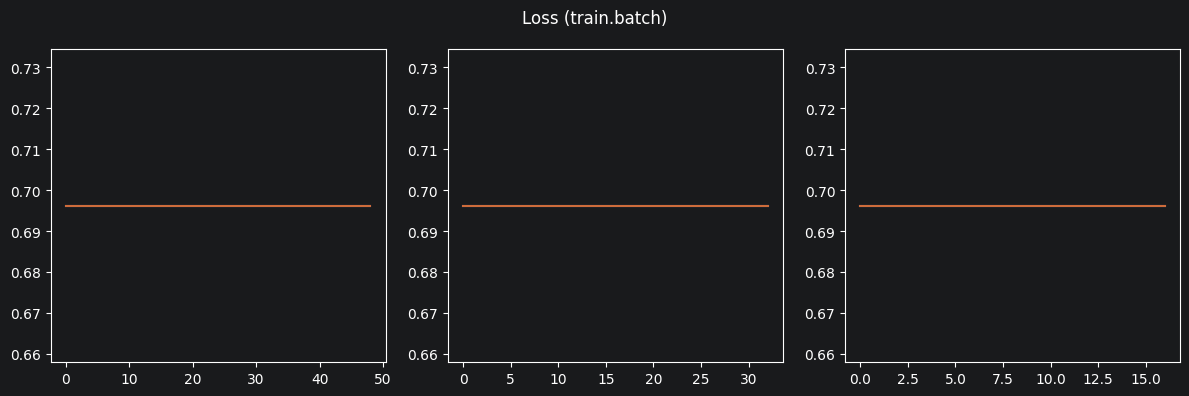

In [249]:
try:
    trainer.plot_loss(skip=2100)
except:
    traceback.print_exc()

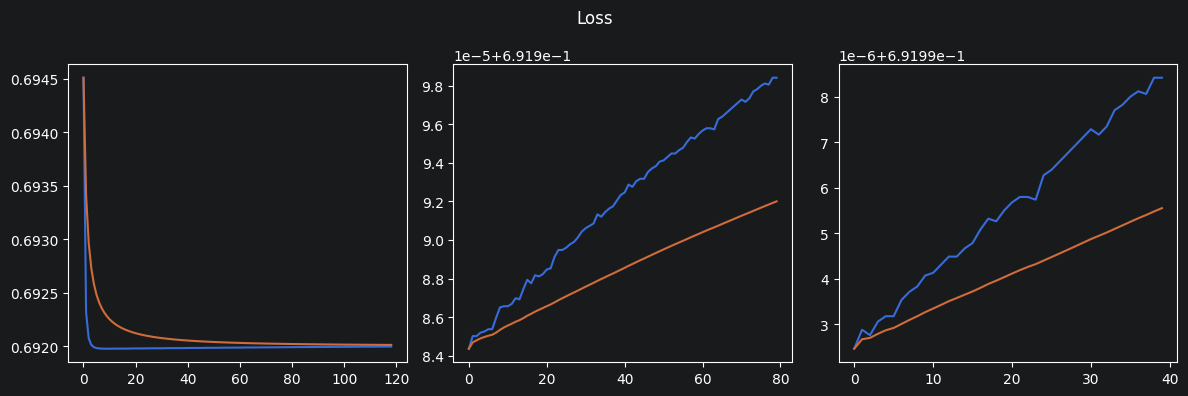

In [240]:
try:
    trainer.plot_loss(trainer.loss['train.batch'][1100::8])
except:
    traceback.print_exc()

In [237]:
try:
    # trainer.loss['train.batch'] = trainer.loss['train.batch'][-25:]
    print(len(trainer.loss['train.batch']))
except:
    traceback.print_exc()

2048


In [94]:
try:
    with torch.no_grad():
        (uid, uft, hid, hft, hcl, msk, lns), (iem, ibs, clk) = next(iter(DataLoader(
            umd, batch_size=1,
            shuffle=True,
            collate_fn=create_sequence_collator((False, False, True, True, True)))))

        print(uid.shape, uft.shape, hid.shape, hft.shape, hcl.shape, msk.shape, lns.shape)

        uem, ubs = user_model(uid, uft)
        print("Without History (w/o b)", (uem * iem).sum())
        print("Without History (w/  b)", (uem * iem).sum() + ubs + ibs)

        pref = torch.tensor(umd.users[uid.item()].preference)
        print("Actual Preference (w/o b)", (pref * iem).sum())
        print("Actual Preference (w/  b)", (pref * iem).sum() + ubs + ibs)
        print("Click", clk)

        pref = torch.tensor(umd.users[uid.item()]._state_vector['preference'])
        print("Original Preference (w/o b)", (pref * iem).sum())
        print("Original Preference (w/  b)", (pref * iem).sum() + ubs + ibs)

        alpha = recommender.alpha(uem)
        print('history weight', 1 - alpha)

        uem2, (ubs2, hbs) = recommender(uid, uft, hid, hft, hcl, msk, lns)
        print("With History (w/o b)", (uem2 * iem).sum())
        print("With History (w/  b)", (uem2 * iem).sum() + ubs2 + ibs)
        # print("With History", (uem2 * iem).sum() + ubs2 + ibs + hbs)

        print("bce_loss", bce_loss((uem2, (ubs2, hbs)), (iem, ibs, clk.unsqueeze(-1))))

except:
    traceback.print_exc()

torch.Size([1]) torch.Size([1, 1582]) torch.Size([1, 19]) torch.Size([1, 19, 429]) torch.Size([1, 19]) torch.Size([1, 19]) torch.Size([1])
Without History (w/o b) tensor(0.2716)
Without History (w/  b) tensor([[0.1416]])
Actual Preference (w/o b) tensor(11.5506)
Actual Preference (w/  b) tensor([[11.4206]])
Click tensor([1.])
Original Preference (w/o b) tensor(0.2716)
Original Preference (w/  b) tensor([[0.1416]])
history weight tensor([[0.7392]])
With History (w/o b) tensor(9.8072)
With History (w/  b) tensor([[9.6772]])
bce_loss tensor(6.2695e-05)


In [198]:
try:
    # print(uem2.sum().backward(retain_graph=True))
    print(list(history_model.parameters())[0].grad)
    # print(len(trainer.loss['batch.train']))
    # trainer.loss['batch.train'] = trainer.loss['batch.train'][5:]
except:
    traceback.print_exc()

tensor([[-2.5513e-10,  2.0903e-10,  1.4617e-10,  ..., -3.8662e-10,
          3.1453e-10,  1.3565e-09],
        [ 1.2437e-13,  1.0329e-13,  3.9263e-15,  ..., -1.9716e-13,
         -2.1419e-13,  3.9213e-13],
        [ 2.0257e-14,  5.1562e-15, -3.1627e-16,  ..., -1.0164e-14,
          8.6443e-15,  6.1078e-14],
        ...,
        [ 2.6706e-08,  6.7275e-06, -9.8218e-06,  ..., -4.1998e-06,
         -3.9737e-07,  8.1171e-06],
        [ 2.4323e-11,  2.8510e-11,  1.1987e-10,  ...,  2.5916e-11,
          4.2523e-11, -7.4768e-10],
        [ 2.2491e-04, -9.4548e-05,  4.3478e-04,  ..., -7.6579e-06,
          2.5283e-04, -6.7242e-04]])


In [95]:
try:
    trainer.save_model("recommender_v5")
    trainer.save_loss("recommender_v5")
except:
    traceback.print_exc()